
# Reconstruction of a Cambered NACA 4-Digit Airfoil

## Objectives

- Generate a cambered NACA 4-digit airfoil using randomly selected parameters.
- Select N points along the airfoil chord.
- Reconstruct the upper and lower surfaces using Lagrange interpolation.
- Compare the original and reconstructed airfoil geometries.
- Calculate maximum absolute error and root mean square (RMS) error.
- Investigate the effect of interpolation point spacing.
- Implement cubic spline interpolation and compare its accuracy with Lagrange interpolation.



In [24]:

import numpy as np
import matplotlib.pyplot as plt



## 2. Generate a Random Cambered NACA 4-Digit Airfoil

The NACA 4-digit designation is represented by three parameters:

- Maximum camber, \(m\), as a fraction of the chord.
- Location of maximum camber, \(p\), as a fraction of the chord.
- Maximum thickness, \(t\), as a fraction of the chord.

The airfoil is generated using the standard NACA equations for the camber line and thickness distribution. The upper and lower surfaces are calculated from these equations.


In [25]:

rng = np.random.default_rng(42)

m = rng.integers(1, 6) / 100
p = rng.integers(2, 7) / 10
t = rng.integers(8, 19) / 100

naca_code = f"{int(m * 100)}{int(p * 10)}{int(t * 100):02d}"

print("NACA airfoil:", naca_code)
print(f"Maximum camber: {m * 100:.1f}%")
print(f"Location of maximum camber: {p * 100:.1f}% chord")
print(f"Maximum thickness: {t * 100:.1f}%")

def naca_airfoil(x, m, p, t):
    x = np.asarray(x, dtype=float)

    yt = 5 * t * (
        0.2969 * np.sqrt(x)
        - 0.1260 * x
        - 0.3516 * x**2
        + 0.2843 * x**3
        - 0.1015 * x**4
    )

    yc = np.where(
        x < p,
        m / p**2 * (2 * p * x - x**2),
        m / (1 - p)**2 * ((1 - 2 * p) + 2 * p * x - x**2)
    )

    dyc_dx = np.where(
        x < p,
        2 * m / p**2 * (p - x),
        2 * m / (1 - p)**2 * (p - x)
    )

    theta = np.arctan(dyc_dx)

    xu = x - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)

    xl = x + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    return xu, yu, xl, yl

x_true = np.linspace(0, 1, 1001)

xu_true, yu_true, xl_true, yl_true = naca_airfoil(
    x_true, m, p, t
)


NACA airfoil: 1515
Maximum camber: 1.0%
Location of maximum camber: 50.0% chord
Maximum thickness: 15.0%


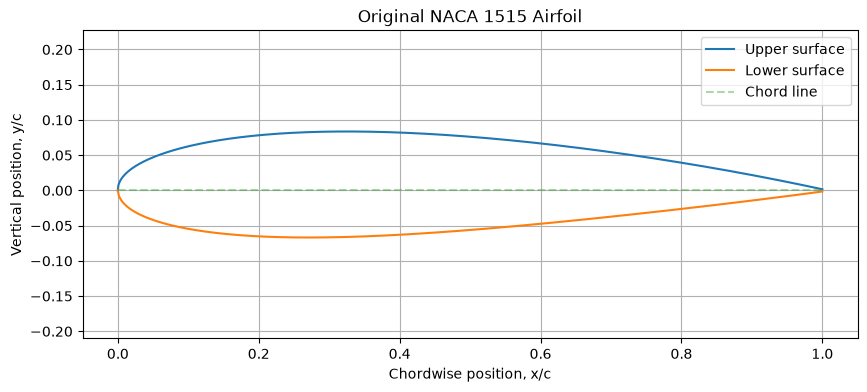

In [26]:

plt.figure(figsize=(10, 4))

plt.plot(xu_true, yu_true, label="Upper surface")
plt.plot(xl_true, yl_true, label="Lower surface")
plt.plot(x_true, np.zeros_like(x_true), "--", alpha=0.4, label="Chord line")

plt.xlabel("Chordwise position, x/c")
plt.ylabel("Vertical position, y/c")
plt.title(f"Original NACA {naca_code} Airfoil")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()



## 4. Reconstruct the Airfoil Using Lagrange Interpolation

Lagrange interpolation estimates a function from a set of known data points using a polynomial passing through those points.

The interpolating polynomial is

$$
P(x) = \sum_{i=0}^{N-1} y_i L_i(x)
$$

where

$$
L_i(x) = \prod_{\substack{j=0 \\ j \ne i}}^{N-1}
\frac{x-x_j}{x_i-x_j}
$$

Here, $x_i$ and $y_i$ are the sampled coordinates, and $N$ is the number of interpolation points.

The following function implements the `Lagrng()` interpolation function for the upper and lower airfoil surfaces.


In [33]:

def Lagrng(x_data, y_data, x_eval):
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    x_eval = np.asarray(x_eval, dtype=float)

    result = np.zeros_like(x_eval)

    for i in range(len(x_data)):
        basis = np.ones_like(x_eval)

        for j in range(len(x_data)):
            if i != j:
                basis *= (x_eval - x_data[j]) / (x_data[i] - x_data[j])

        result += y_data[i] * basis

    return result



## 5. Select N Points and Reconstruct the Airfoil

Select a small number of points along the chord, calculate their corresponding upper and lower surface coordinates, and apply Lagrange interpolation to reconstruct the geometry.

Cosine spacing places more points near the leading and trailing edges, where the airfoil geometry changes more rapidly.


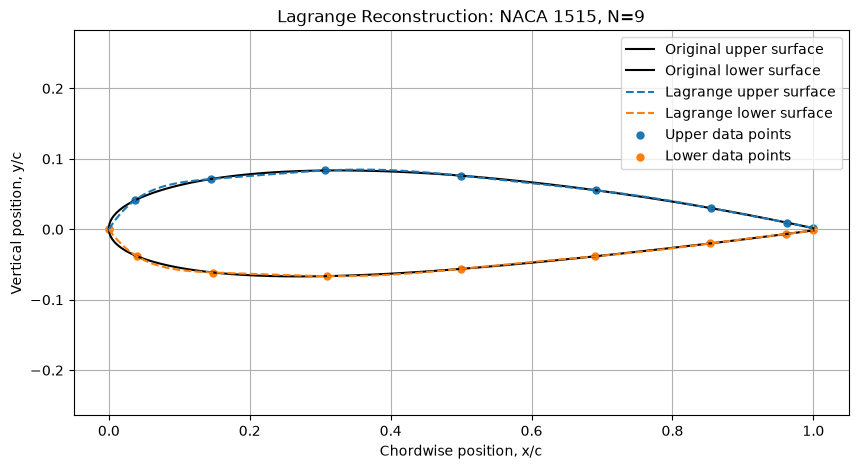

In [34]:

N = 9

theta_points = np.linspace(0, np.pi, N)
x_points = (1 - np.cos(theta_points)) / 2

xu_points, yu_points, xl_points, yl_points = naca_airfoil(
    x_points, m, p, t
)

yu_lagrange = Lagrng(xu_points, yu_points, xu_true)
yl_lagrange = Lagrng(xl_points, yl_points, xl_true)

plt.figure(figsize=(10, 5))

plt.plot(xu_true, yu_true, "k-", label="Original upper surface")
plt.plot(xl_true, yl_true, "k-", label="Original lower surface")
plt.plot(xu_true, yu_lagrange, "--", label="Lagrange upper surface")
plt.plot(xl_true, yl_lagrange, "--", label="Lagrange lower surface")
plt.scatter(xu_points, yu_points, label="Upper data points", s=25)
plt.scatter(xl_points, yl_points, label="Lower data points", s=25)

plt.xlabel("Chordwise position, x/c")
plt.ylabel("Vertical position, y/c")
plt.title(f"Lagrange Reconstruction: NACA {naca_code}, N={N}")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()



## 6. Quantify the Reconstruction Error

The maximum absolute error measures the largest difference between the original and reconstructed surfaces.

$$
E_{\max} = \max_i \left| y_i - \hat{y}_i \right|
$$

The root mean square (RMS) error measures the average magnitude of the reconstruction error.

$$
E_{\mathrm{RMS}} =
\sqrt{\frac{1}{n}\sum_{i=1}^{n}
\left(y_i-\hat{y}_i\right)^2}
$$

Here, $y_i$ represents the original surface coordinates, $\hat{y}_i$ represents the reconstructed surface coordinates, and $n$ is the total number of evaluation points.

The errors are calculated by comparing the original and reconstructed geometries on a dense grid.


In [36]:

def calculate_errors(y_true, y_pred):
    error = np.asarray(y_true) - np.asarray(y_pred)

    max_error = np.max(np.abs(error))
    rms_error = np.sqrt(np.mean(error**2))

    return max_error, rms_error

max_upper, rms_upper = calculate_errors(yu_true, yu_lagrange)
max_lower, rms_lower = calculate_errors(yl_true, yl_lagrange)

max_lagrange = max(max_upper, max_lower)
rms_lagrange = np.sqrt(
    (np.mean((yu_true - yu_lagrange)**2)
     + np.mean((yl_true - yl_lagrange)**2)) / 2
)

print(f"Maximum upper surface error: {max_upper:.8f}")
print(f"RMS upper surface error: {rms_upper:.8f}")
print(f"Maximum lower surface error: {max_lower:.8f}")
print(f"RMS lower surface error: {rms_lower:.8f}")
print(f"Overall maximum error: {max_lagrange:.8f}")
print(f"Overall RMS error: {rms_lagrange:.8f}")


Maximum upper surface error: 0.00890490
RMS upper surface error: 0.00185068
Maximum lower surface error: 0.00771590
RMS lower surface error: 0.00153580
Overall maximum error: 0.00890490
Overall RMS error: 0.00170055



## 7. Investigate the Effect of Point Spacing

Compare uniformly spaced points with cosine-spaced points for different values of N.

- Uniform spacing distributes the points equally along the chord.
- Cosine spacing concentrates points near the leading and trailing edges.
- For each spacing method, calculate the maximum absolute error and RMS error.

This comparison helps identify how the number and distribution of data points influence the accuracy of global Lagrange interpolation.


Uniform  N= 5 | Max error=1.88394738e-02 | RMS error=5.78311920e-03
Uniform  N= 7 | Max error=1.42300782e-02 | RMS error=3.32157162e-03
Uniform  N= 9 | Max error=1.17400157e-02 | RMS error=2.27036330e-03
Uniform  N=11 | Max error=1.01479566e-02 | RMS error=1.70111446e-03
Uniform  N=13 | Max error=9.02817677e-03 | RMS error=1.34968978e-03
Cosine   N= 5 | Max error=1.65197816e-02 | RMS error=5.32993959e-03
Cosine   N= 7 | Max error=1.12288701e-02 | RMS error=2.76269301e-03
Cosine   N= 9 | Max error=8.54274317e-03 | RMS error=1.71512071e-03
Cosine   N=11 | Max error=6.91203001e-03 | RMS error=1.18617038e-03
Cosine   N=13 | Max error=5.83715097e-03 | RMS error=8.83204130e-04


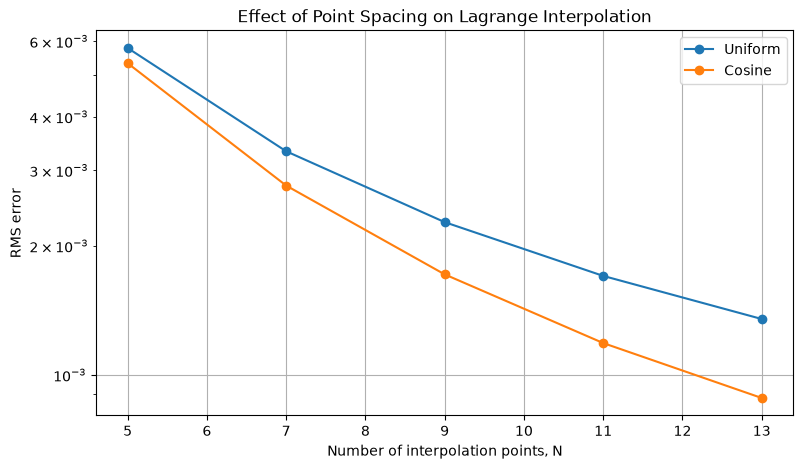

In [37]:

def reconstruct_lagrange(N, spacing):
    if spacing == "Uniform":
        x = np.linspace(0, 1, N)
    elif spacing == "Cosine":
        theta = np.linspace(0, np.pi, N)
        x = (1 - np.cos(theta)) / 2

    xu, yu, xl, yl = naca_airfoil(x, m, p, t)

    yu_rec = Lagrng(xu, yu, x_true)
    yl_rec = Lagrng(xl, yl, x_true)

    max_u, rms_u = calculate_errors(yu_true, yu_rec)
    max_l, rms_l = calculate_errors(yl_true, yl_rec)

    max_error = max(max_u, max_l)
    rms_error = np.sqrt(
        (rms_u**2 + rms_l**2) / 2
    )

    return max_error, rms_error

point_counts = [5, 7, 9, 11, 13]
results = {}

for spacing in ["Uniform", "Cosine"]:
    results[spacing] = []

    for n in point_counts:
        max_error, rms_error = reconstruct_lagrange(n, spacing)

        results[spacing].append((max_error, rms_error))

        print(
            f"{spacing:8s} N={n:2d} | "
            f"Max error={max_error:.8e} | "
            f"RMS error={rms_error:.8e}"
        )

plt.figure(figsize=(9, 5))

for spacing in ["Uniform", "Cosine"]:
    rms_errors = [r[1] for r in results[spacing]]
    plt.plot(point_counts, rms_errors, "o-", label=spacing)

plt.xlabel("Number of interpolation points, N")
plt.ylabel("RMS error")
plt.title("Effect of Point Spacing on Lagrange Interpolation")
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.show()



## 8. Reconstruct the Airfoil Using Cubic Splines

Cubic spline interpolation uses separate cubic polynomials between consecutive data points. The polynomials are joined so that the function and its first and second derivatives remain continuous at the interior data points.

A natural cubic spline imposes zero second derivatives at the two endpoints.

Unlike global Lagrange interpolation, a cubic spline is a piecewise polynomial. It often provides a smoother reconstruction without the strong oscillations that can occur when using a high-degree global polynomial.

The following function implements a natural cubic spline without requiring SciPy.


In [38]:

def cubic_spline(x_data, y_data, x_eval):
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    x_eval = np.asarray(x_eval, dtype=float)

    n = len(x_data)

    if n < 3:
        raise ValueError("At least three data points are required.")

    if np.any(np.diff(x_data) <= 0):
        raise ValueError("Data points must be strictly increasing.")

    h = np.diff(x_data)
    alpha = np.zeros(n)

    alpha[1:-1] = (
        3 / h[1:] * (y_data[2:] - y_data[1:-1])
        - 3 / h[:-1] * (y_data[1:-1] - y_data[:-2])
    )

    l = np.ones(n)
    mu = np.zeros(n)
    z = np.zeros(n)

    for i in range(1, n - 1):
        l[i] = 2 * (x_data[i + 1] - x_data[i - 1]) - h[i - 1] * mu[i - 1]
        mu[i] = h[i] / l[i]
        z[i] = (alpha[i] - h[i - 1] * z[i - 1]) / l[i]

    c = np.zeros(n)
    b = np.zeros(n - 1)
    d = np.zeros(n - 1)

    for j in range(n - 2, -1, -1):
        c[j] = z[j] - mu[j] * c[j + 1]
        b[j] = (
            (y_data[j + 1] - y_data[j]) / h[j]
            - h[j] * (c[j + 1] + 2 * c[j]) / 3
        )
        d[j] = (c[j + 1] - c[j]) / (3 * h[j])

    indices = np.searchsorted(x_data, x_eval, side="right") - 1
    indices = np.clip(indices, 0, n - 2)

    dx = x_eval - x_data[indices]

    y_eval = (
        y_data[indices]
        + b[indices] * dx
        + c[indices] * dx**2
        + d[indices] * dx**3
    )

    return y_eval



## 9. Compare Lagrange and Cubic Spline Reconstruction

Use the same sampled airfoil points for both interpolation methods. Plot both reconstructed geometries against the original airfoil, then calculate their maximum absolute and RMS errors.

Using the same data points ensures that the comparison reflects the interpolation methods rather than a difference in sampling.


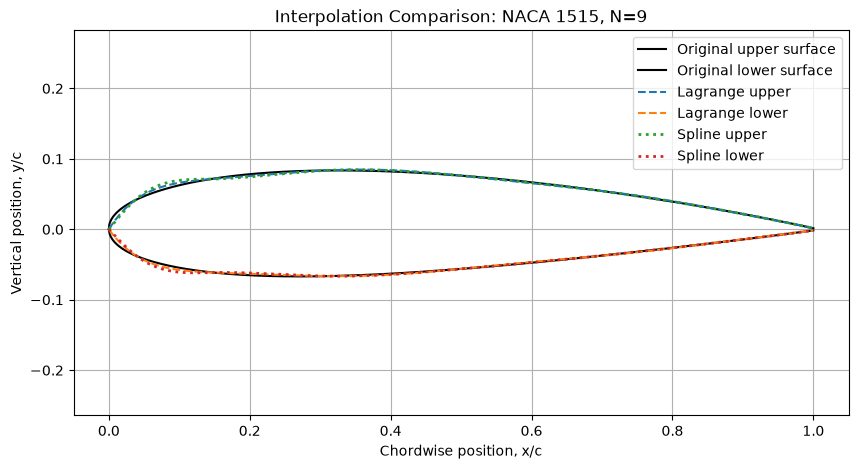

Interpolation error comparison
------------------------------------------------
Method               Maximum error     RMS error
------------------------------------------------
Lagrange            8.90489980e-031.70054512e-03
Cubic spline        1.05825122e-022.48124061e-03


In [39]:

yu_spline = cubic_spline(xu_points, yu_points, xu_true)
yl_spline = cubic_spline(xl_points, yl_points, xl_true)

plt.figure(figsize=(10, 5))

plt.plot(xu_true, yu_true, "k-", label="Original upper surface")
plt.plot(xl_true, yl_true, "k-", label="Original lower surface")
plt.plot(xu_true, yu_lagrange, "--", label="Lagrange upper")
plt.plot(xl_true, yl_lagrange, "--", label="Lagrange lower")
plt.plot(xu_true, yu_spline, ":", linewidth=2, label="Spline upper")
plt.plot(xl_true, yl_spline, ":", linewidth=2, label="Spline lower")

plt.xlabel("Chordwise position, x/c")
plt.ylabel("Vertical position, y/c")
plt.title(f"Interpolation Comparison: NACA {naca_code}, N={N}")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

max_lag = max(
    np.max(np.abs(yu_true - yu_lagrange)),
    np.max(np.abs(yl_true - yl_lagrange))
)

rms_lag = np.sqrt(
    (
        np.mean((yu_true - yu_lagrange)**2)
        + np.mean((yl_true - yl_lagrange)**2)
    ) / 2
)

max_spline = max(
    np.max(np.abs(yu_true - yu_spline)),
    np.max(np.abs(yl_true - yl_spline))
)

rms_spline = np.sqrt(
    (
        np.mean((yu_true - yu_spline)**2)
        + np.mean((yl_true - yl_spline)**2)
    ) / 2
)

print("Interpolation error comparison")
print("-" * 48)
print(f"{'Method':<20}{'Maximum error':>14}{'RMS error':>14}")
print("-" * 48)
print(f"{'Lagrange':<20}{max_lag:>14.8e}{rms_lag:>14.8e}")
print(f"{'Cubic spline':<20}{max_spline:>14.8e}{rms_spline:>14.8e}")




## 10. Conclusions

- A randomly selected cambered NACA 4-digit airfoil was generated using the standard airfoil equations.
- Lagrange interpolation was used to reconstruct the upper and lower surfaces from a limited number of points.
- The maximum absolute error and RMS error were calculated to quantify reconstruction accuracy.
- Uniform and cosine spacing were compared to investigate the influence of point distribution.
- A natural cubic spline interpolation function was implemented and evaluated using the same data points as Lagrange interpolation.
- The reconstruction errors can be used to determine which interpolation method and point distribution provide better accuracy for the selected airfoil.

The best interpolation method should be selected based on the calculated errors and the smoothness of the reconstructed geometry.

    